<a href="https://colab.research.google.com/github/PacktPublishing/Hands-On-Open-Source-Foundation-Models-for-Time-Series-Forecasting/blob/main/Chapter03_Zero_Shot_Forecasting/04_train_test_splits.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 04 · Train and test splits

*Hands-On Open-Source Foundation Models for Time Series Forecasting*, Chapter 3: Zero-Shot Forecasting in Practice

Before any model makes a forecast, we have to decide which part of each dataset it is allowed to read and which
part it will be judged on. This notebook makes that decision once, for every dataset and every forecast horizon,
and writes it to a file that all the forecasting notebooks read. The part a model may read is the *context* (the
"train" part); the part it is scored on is the *test window*.

The notebook also shows its work. It prints the rows on both sides of every boundary, draws the test windows on a
timeline, checks that no covariate carries information from the future, and flags the test windows that a
pre-trained model could in principle have seen during its training.

#### Why this matters for zero-shot forecasting

A zero-shot model is never trained on our data, so the usual "train set" becomes the model's *input*: the history
it looks at before it forecasts. Two things can still go wrong. The input can contain information from the test
period, for example a covariate computed with future values or two windows that overlap. And the large collection
of series the model was pre-trained on may already contain the test period itself. Both make scores look better
than they are, and neither shows up in the scores. Fixing the splits here, and checking for both problems, makes
every later comparison fair and repeatable.

The notebook covers all six datasets: D1 and D2 (daily temperature, without and with covariates), D3 and D4
(monthly metal prices, without and with drivers), B1 (WTI oil price, trading days) and B2 (Treasury yields,
trading days). The numbers quoted in the text come from the data snapshot of 30 September 2026, downloaded on
1 November 2026.

**What you will learn**

- how a single fixed test window and a set of rolling test windows are defined, with their formulas
- why the test windows of one horizon must not overlap, and how many forecast errors each design gives
- the difference between covariates known in advance and covariates observed only as time passes, and how to check
  a split for leakage
- how the date a model's weights were saved tells you what it can and cannot have seen

| Environment and compute | |
|---|---|
| Python | 3.12 or 3.13 (Google Colab runs 3.13) |
| Packages | [`requirements-dataprep.txt`](requirements-dataprep.txt) (pinned versions); on Colab the setup cell adds the few that Colab lacks ([`requirements-colab.txt`](requirements-colab.txt)) |
| Hardware | CPU only (Colab free tier is enough) |
| Network | none: reads the frozen datasets in `input_timeseries/` |
| Run time | under 1 minute on 4 CPU cores (Colab's free tier has 2: allow up to twice as long) |
| Peak memory | 0.2 GB (kernel peak) |

**How to run this notebook**

- **Google Colab:** choose *Runtime > Run all*. The first code cell fetches this chapter's folder and installs the
  packages Colab does not have (about a minute). If it says it is restarting the session, wait, then choose
  *Runtime > Run all* again. To use your own copy on Google Drive, set `DRIVE_COPY` in that cell to the folder's path.
- **Your own computer (Cursor, VS Code or Jupyter):** create an environment with
  `uv venv .venv-dataprep -p 3.12 && uv pip install -p .venv-dataprep -r requirements-dataprep.txt` (or
  `python -m venv .venv-dataprep` and `pip install -r ...`), open this folder, choose that environment's kernel and run
  all cells.

In [1]:
# Setup: find this chapter's folder (on Colab: fetch it and install the packages Colab lacks)
import os
import sys
from pathlib import Path

CHAPTER = "Chapter03_Zero_Shot_Forecasting"   # this chapter's folder in the book's repository
DRIVE_COPY = ""   # Colab only, optional: path of your own copy of this folder on Google Drive
IN_COLAB = "google.colab" in sys.modules


def is_chapter(d):
    return (Path(d) / "src" / "ch03_dataprep" / "__init__.py").is_file()


if IN_COLAB:
    import importlib.metadata as md
    import shutil

    BOOK = Path("/content/book")

    def chapter_dir():
        return next((d for d in (BOOK / CHAPTER, BOOK) if is_chapter(d)), None)

    def find_in_drive(top="/content/drive/MyDrive", depth=6):   # copies of CHAPTER, shallowest first
        level = [top]
        for _ in range(depth):
            subdirs = []
            for d in level:
                try:
                    subdirs += [e.path for e in os.scandir(d) if e.is_dir() and not e.name.startswith(".")]
                except OSError:
                    pass
            hits = [d for d in subdirs if Path(d).name == CHAPTER and is_chapter(d)]
            if hits:
                return hits
            level = subdirs
        return []

    if chapter_dir() is None and not DRIVE_COPY:      # 1) clone the book's repository
        shutil.rmtree(BOOK, ignore_errors=True)
        !GIT_TERMINAL_PROMPT=0 git clone -q --depth 1 https://github.com/PacktPublishing/Hands-On-Open-Source-Foundation-Models-for-Time-Series-Forecasting /content/book
    if chapter_dir() is None:                         # 2) not on GitHub (yet): copy it from Google Drive
        from google.colab import drive
        drive.mount("/content/drive")
        if not DRIVE_COPY:
            hits = find_in_drive()
            if len(hits) > 1:
                raise FileExistsError(f"several copies of {CHAPTER} in My Drive: {hits}. Set DRIVE_COPY to one.")
            DRIVE_COPY = hits[0] if hits else ""
        if not DRIVE_COPY or not is_chapter(DRIVE_COPY):
            raise FileNotFoundError(f"{CHAPTER} is not on GitHub or in your Google Drive. Set DRIVE_COPY to its path.")
        shutil.rmtree(BOOK, ignore_errors=True)
        shutil.copytree(DRIVE_COPY, BOOK / CHAPTER,
                        ignore=lambda d, names: [n for n in names if n.startswith(".venv") or n == "__pycache__"])
    os.chdir(chapter_dir())
    loaded = {name: md.version(name) for name in ("numpy", "pandas", "scipy", "statsmodels")}
    # Install with uv, several times faster than pip. Colab comes with uv (installed here if not). The settings point
    # uv at Colab's own Python and drop install constraints left over from building Colab's image; pip is the fallback.
    if shutil.which("uv") is None:
        %pip install -q uv
    for name in ("UV_CONSTRAINT", "UV_BUILD_CONSTRAINT", "UV_PRERELEASE"):
        os.environ.pop(name, None)
    os.environ.update(UV_PYTHON=sys.executable, UV_SYSTEM_PYTHON="1", UV_BREAK_SYSTEM_PACKAGES="1")
    !uv pip install -q -r requirements-colab.txt || {sys.executable} -m pip install -q -r requirements-colab.txt
    changed = [name for name, version in loaded.items() if md.version(name) != version]
    if changed:   # Colab had already imported the old version: restart once so Python loads the new one
        print(f"The install updated {', '.join(changed)}: restarting the session. Then choose Runtime > Run all again.")
        get_ipython().kernel.do_shutdown(True)
        raise SystemExit

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if is_chapter(p))
sys.path.insert(0, str(ROOT / "src"))
os.chdir(ROOT)
DATA, RESULTS = ROOT / "data", ROOT / "results"
INPUT = ROOT / "input_timeseries"   # the frozen datasets (CSV) and the data dictionary
print(f"chapter folder: {ROOT}  |  Python {sys.version.split()[0]}  |  Colab: {IN_COLAB}")

chapter folder: /home/user/v3/Chapter03_Zero_Shot_Forecasting  |  Python 3.13.18  |  Colab: False


In [2]:
from pathlib import Path

FRED_CSV = "https://fred.stlouisfed.org/graph/fredgraph.csv?id={series}"
HADCET_PAGE = "https://www.metoffice.gov.uk/hadobs/hadcet/data/download.html"
HADCET_FILE = "meantemp_daily_totals.txt"
CPC_NAO = "https://ftp.cpc.ncep.noaa.gov/cwlinks/norm.daily.nao.cdas.z500.19500101_current.csv"
CPC_AO = "https://ftp.cpc.ncep.noaa.gov/cwlinks/norm.daily.ao.cdas.z1000.19500101_current.csv"
PINK_SHEET_PAGE = "https://www.worldbank.org/en/research/commodity-markets"
# direct link to the same workbook (checked 1 Nov 2026: "Updated on October 02, 2026"); used if the page is unreachable
PINK_SHEET_URL = ("https://thedocs.worldbank.org/en/doc/74e8be41ceb20fa0da750cda2f6b9e4e-0050012026/related/"
                  "CMO-Historical-Data-Monthly.xlsx")

N_DAILY = 10_000            # most recent observations kept for daily data
MONTHLY_START = "1982-01-01"  # first month of the Cleveland Fed real-rate series
HORIZONS = {"daily": [7, 14, 30, 60, 90], "monthly": [3, 6, 9, 12, 24]}
ROLLING_WINDOWS = {"daily": {7: 5, 14: 5, 30: 5, 60: 5, 90: 5},
                   "monthly": {3: 3, 6: 3, 9: 3, 12: 3, 24: 1}}
HADCET_LAT = 52.5           # latitude used for day length (degrees north)

METALS = {  # column: (World Bank Pink Sheet column, FRED id of the IMF series used as a cross-check, description)
    "copper": ("Copper", "PCOPPUSDM", "Copper (LME), grade A cathodes, USD per metric ton"),
    "aluminium": ("Aluminum", "PALUMUSDM", "Aluminium (LME), primary ingots 99.7 %, USD per metric ton"),
    "nickel": ("Nickel", "PNICKUSDM", "Nickel (LME), cathodes 99.8 %, USD per metric ton"),
    "zinc": ("Zinc", "PZINCUSDM", "Zinc (LME), high grade 99.95 %, USD per metric ton"),
    "lead": ("Lead", "PLEADUSDM", "Lead (LME), refined 99.97 %, USD per metric ton"),
}
DRIVERS = {  # column: (FRED id, fallback FRED id, description)
    "global_activity": ("IGREA", None, "Kilian index of global real economic activity (% deviation from trend)"),
    "usd": ("NNUSBIS", "TWEXBGSMTH", "US dollar nominal effective exchange rate, BIS narrow index (2020 = 100)"),
    "real_rate_10y": ("REAINTRATREARAT10Y", "DFII10", "US 10-year real interest rate, Cleveland Fed (%)"),
}
TREASURY = {"y3m": "DGS3MO", "y1": "DGS1", "y2": "DGS2", "y5": "DGS5", "y10": "DGS10"}
WTI = "DCOILWTICO"

DATASETS = {
    "D1": {"name": "Central England Temperature, daily mean", "kind": "U", "grain": "daily",
           "targets": ["temp"], "covariates": []},
    "D2": {"name": "Central England Temperature + covariates", "kind": "U+X", "grain": "daily",
           "targets": ["temp"],
           "known_future": ["fourier_sin_1", "fourier_cos_1", "fourier_sin_2", "fourier_cos_2",
                            "fourier_sin_3", "fourier_cos_3", "daylength_h"],
           "past_only": ["wav_d1_2", "wav_d3_4", "wav_d5_6", "wav_d7_8", "wav_s8", "nao", "ao"]},
    "D3": {"name": "Base-metal prices, monthly", "kind": "MV", "grain": "monthly",
           "targets": list(METALS), "covariates": []},
    "D4": {"name": "Base metals + global drivers", "kind": "MV+X", "grain": "monthly",
           "targets": list(METALS), "known_future": [], "past_only": list(DRIVERS)},
    "B1": {"name": "WTI crude oil, daily spot", "kind": "U", "grain": "trading day",
           "targets": ["wti"], "covariates": []},
    "B2": {"name": "US Treasury yield curve, daily", "kind": "MV", "grain": "trading day",
           "targets": list(TREASURY), "covariates": []},
}


def find_root(start=None):
    """The chapter folder: the one that holds src/ch03_dataprep and data/."""
    here = Path(start or Path.cwd()).resolve()
    for p in [here, *here.parents]:
        if (p / "src" / "ch03_dataprep").is_dir() and (p / "data").is_dir():
            return p
    raise FileNotFoundError("Run the notebook from inside the Chapter 3 folder.")


def grain_key(dataset_id):
    """'daily' for daily and trading-day data, 'monthly' otherwise."""
    return "monthly" if DATASETS[dataset_id]["grain"] == "monthly" else "daily"

In [3]:
import json
import warnings

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

from ch03_dataprep.plotting import INK_2, SERIES as COLORS, SURFACE, set_style

warnings.filterwarnings("ignore")
set_style()
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 20)

SNAP = {name: pd.read_csv(INPUT / f"{name}.csv", index_col=0, parse_dates=True) for name in DATASETS}
SNAPSHOT = json.loads((INPUT / "snapshot_manifest.json").read_text())
COVARIATES = SNAPSHOT["covariates"]     # the covariate lists actually built in Notebook 00
print(f"snapshot of {SNAPSHOT['vintage_cut']} (built {SNAPSHOT['built_utc'][:10]})")
for name, frame in SNAP.items():
    print(f"{name}: {len(frame):6,} rows, {frame.index[0].date()} to {frame.index[-1].date()}, "
          f"{frame.shape[1]} columns, grain: {DATASETS[name]['grain']}")

snapshot of 2026-09-30 (built 2026-11-01)
D1: 10,000 rows, 1999-05-16 to 2026-09-30, 1 columns, grain: daily
D2: 10,000 rows, 1999-05-16 to 2026-09-30, 13 columns, grain: daily
D3:    535 rows, 1982-01-01 to 2026-07-01, 5 columns, grain: monthly
D4:    535 rows, 1982-01-01 to 2026-07-01, 8 columns, grain: monthly
B1:  9,513 rows, 1986-01-02 to 2026-09-30, 1 columns, grain: trading day
B2: 10,000 rows, 1986-10-08 to 2026-09-30, 5 columns, grain: trading day


## 1 · The split design

#### Notation

A dataset has rows $t = 1, \dots, N$ (days, trading days or months). For a horizon $H$ and a window number
$r = 1, \dots, R$, the forecast origin, the last row the model may read, is

$$T_r = N - rH .$$

The model reads the **context** $y_1, \dots, y_{T_r}$, plus whichever covariates are allowed at that origin, and
forecasts the **test window** $y_{T_r + 1}, \dots, y_{T_r + H}$. Its errors are measured on that window only.

#### One fixed window and several rolling ones

Window $r = 1$ is the **fixed origin**: the last $H$ rows of the dataset form the test window. This is the
*primary* split, with one forecast per series and horizon, the same for every model.

Windows $r = 2, \dots, R$ are **rolling origins**. Each one moves the origin back by a whole horizon, so the $R$ test
windows of one horizon sit end to end and **never overlap**. Each origin uses all the history before it, so the
context grows as the origin moves forward. A score averaged over several origins depends less on one particular
stretch of data, which is the main reason to evaluate on rolling origins.

Why insist that the windows do not overlap? Overlapping windows share test points, so their errors are correlated,
and an average over them looks like more evidence than it is. With windows that sit end to end, a horizon
contributes exactly $R \cdot H$ distinct test points per series. GIFT-Eval, a public benchmark on which many
foundation models report their results, also scores models on non-overlapping windows at the end of each series.

| Grain | Horizons $H$ | Windows $R$ | Test points per series |
|---|---|---|---|
| daily (D1, D2) and trading day (B1, B2) | 7, 14, 30, 60, 90 | 5 for every $H$ | 35, 70, 150, 300, 450 |
| monthly (D3, D4) | 3, 6, 9, 12, 24 | 3 for $H \le 12$, 1 for $H = 24$ | 9, 18, 27, 36, 24 |

The monthly data are short (535 months), so $H = 24$ keeps a single window: three windows would place the earliest
test window six years before the end of the data. For B1 and B2 a "day" is a trading day, so $H = 30$ means 30
trading days, about six weeks of calendar time.

#### Why we say "context" and not "train"

Nothing is fitted to these rows for a zero-shot model. The statistical baselines (naive, seasonal naive, ETS,
ARIMA) *are* fitted to the same rows, so for them the context is the training set. The same split serves both
kinds of model, and that is what makes the comparison fair.

In [4]:
import pandas as pd


def windows_for(grain, horizon, rolling_windows):
    """Number of rolling windows R for a grain and horizon (plan section 5)."""
    return int(rolling_windows[grain][horizon])


def make_splits(index, dataset, grain, horizons, rolling_windows):
    """One row per (horizon, window): origin T_r = N - r H, context 1..T_r, test T_r+1..T_r+H.

    Window r = 1 is the primary (fixed-origin) split; r = 2..R move the origin
    back by whole horizons, so the R test windows of a horizon never overlap.
    Positions are 0-based row numbers; dates are the index values at them.
    """
    idx = pd.DatetimeIndex(index)
    n = len(idx)
    rows = []
    for h in horizons:
        for r in range(1, windows_for(grain, h, rolling_windows) + 1):
            origin = n - r * h            # number of context rows, T_r
            rows.append({
                "dataset": dataset, "grain": grain, "horizon": h, "window": r,
                "primary": r == 1, "origin_date": idx[origin - 1],
                "context_start": idx[0], "context_end": idx[origin - 1],
                "test_start": idx[origin], "test_end": idx[origin + h - 1],
                "n_context": origin, "n_test": h,
            })
    return pd.DataFrame(rows)


def insample_end(manifest):
    """Last date before the earliest test window of any split: the end of the
    sample that exploratory analysis (NB02 wavelet coherence) may use."""
    earliest = manifest["test_start"].min()
    ends = manifest.loc[manifest["test_start"] == earliest, "context_end"]
    return ends.iloc[0]


def split_frame(frame, row, past_only=(), known_future=()):
    """Model inputs for one manifest row.

    Returns (context, future, test):
      context: target and every covariate up to the origin (rows 1..T);
      future:  known-future covariates over the test window (rows T+1..T+H);
               past-only covariates are never included here;
      test:    the target over the test window (used only for scoring).
    """
    t = int(row["n_context"])
    h = int(row["n_test"])
    context = frame.iloc[:t]
    future = frame.iloc[t:t + h][list(known_future)]
    test = frame.iloc[t:t + h].drop(columns=list(past_only) + list(known_future), errors="ignore")
    assert_no_leakage(context, future, test, row, past_only)
    return context, future, test


def assert_no_leakage(context, future, test, row, past_only=()):
    """Leakage checks: the context ends at the origin, the test window starts the
    next row, and no past-only covariate appears in the future block."""
    assert context.index.max() == row["origin_date"], "context does not end at the origin"
    assert test.index.min() == row["test_start"], "test window does not start after the origin"
    assert context.index.max() < test.index.min(), "context overlaps the test window"
    assert not set(past_only) & set(future.columns), "past-only covariate in the future block"
    assert len(test) == row["n_test"], "test window has the wrong length"


def checkpoint_overlap(manifest, checkpoints):
    """For each split, the models whose weights were last committed on or after
    the first test date.

    A checkpoint cannot contain data from after its weights were uploaded, so
    a test window that starts after that date is guaranteed unseen by it.
    Windows that start earlier *could* be in its pre-training corpus (only if
    the corpus contains this series); they are flagged, not excluded.
    """
    dates = pd.to_datetime(checkpoints.set_index("model")["weights_last_commit_utc"])
    out = manifest.copy()
    out["models_weights_after_test_start"] = [
        ", ".join(sorted(dates.index[dates >= ts])) for ts in out["test_start"]]
    out["n_models_flagged"] = [int((dates >= ts).sum()) for ts in out["test_start"]]
    return out

## 2 · Build the splits for all six datasets

`make_splits` returns one row for each pair of horizon and window. Each row holds the origin, the first and last
context date, the first and last test date, and the number of context and test rows. D2 has the same dates as D1,
and D4 the same as D3, so their splits are identical. They are still kept as separate rows, so that each dataset
has its own complete record.

In [5]:
manifest = pd.concat([make_splits(SNAP[name].index, name, grain_key(name), HORIZONS[grain_key(name)], ROLLING_WINDOWS)
                      for name in DATASETS], ignore_index=True)
summary = (manifest.groupby(["dataset", "horizon"])
           .agg(windows=("window", "size"), test_points=("n_test", "sum"),
                context_rows_min=("n_context", "min"), context_rows_max=("n_context", "max"),
                first_test_date=("test_start", "min"), last_test_date=("test_end", "max")))
print(f"{len(manifest)} splits: " + ", ".join(f"{k} {v}" for k, v in manifest.groupby("dataset").size().items()))
summary

126 splits: B1 25, B2 25, D1 25, D2 25, D3 13, D4 13


windows  test_points  context_rows_min  context_rows_max first_test_date last_test_date
dataset horizon                                                                                         
B1      7              5           35              9478              9506      2026-08-12     2026-09-30
        14             5           70              9443              9499      2026-06-23     2026-09-30
        30             5          150              9363              9483      2026-02-26     2026-09-30
        60             5          300              9213              9453      2025-07-21     2026-09-30
        90             5          450              9063              9423      2024-12-10     2026-09-30
B2      7              5           35              9965              9993      2026-08-12     2026-09-30
        14             5           70              9930              9986      2026-06-23     2026-09-30
        30             5          150              9850              9970      2026-02-27     2026-09-30
        60             5          300              9700              9940      2025-07-22     2026-09-30
        90             5          450              9550              9910      2024-12-12     2026-09-30
D1      7              5           35              9965              9993      2026-08-27     2026-09-30
        14             5           70              9930              9986      2026-07-23     2026-09-30
        30             5          150              9850              9970      2026-05-04     2026-09-30
        60             5          300              9700              9940      2025-12-05     2026-09-30
        90             5          450              9550              9910      2025-07-08     2026-09-30
D2      7              5           35              9965              9993      2026-08-27     2026-09-30
        14             5           70              9930              9986      2026-07-23     2026-09-30
        30             5          150              9850              9970      2026-05-04     2026-09-30
        60             5          300              9700              9940      2025-12-05     2026-09-30
        90             5          450              9550              9910      2025-07-08     2026-09-30
D3      3              3            9               526               532      2025-11-01     2026-07-01
        6              3           18               517               529      2025-02-01     2026-07-01
        9              3           27               508               526      2024-05-01     2026-07-01
        12             3           36               499               523      2023-08-01     2026-07-01
        24             1           24               511               511      2024-08-01     2026-07-01
D4      3              3            9               526               532      2025-11-01     2026-07-01
        6              3           18               517               529      2025-02-01     2026-07-01
        9              3           27               508               526      2024-05-01     2026-07-01
        12             3           36               499               523      2023-08-01     2026-07-01
        24             1           24               511               511      2024-08-01     2026-07-01

**What this tells us.** There are 126 splits: 25 for each daily or trading-day dataset (5 horizons × 5 windows) and
13 for each monthly one. Per series and horizon, a daily dataset contributes 35 to 450 test points and a monthly
one 9 to 36.

The shortest contexts are 9,063 rows (B1 at H = 90, window 5) and 499 months (D3 and D4 at H = 12, window 3). How
much of that history a model actually reads depends on its own context limit, which is set in the forecasting
notebooks. The test windows reach back to July 2025 for D1 and D2, December 2024 for B1 and B2, and August 2023 for
D3 and D4.

## 3 · The rows on each side of every boundary

A table of dates can hide an off-by-one error; the values themselves cannot. For each dataset, the first table
shows, for every horizon and window, the **last context row** and the **first and last test rows**, with their
values. The second table shows the full rows around the boundary of the primary split at the longest horizon: the
last three context rows, then the first three and the last three test rows. A model sees the rows marked `context`
and nothing else.

In [6]:
def boundary_table(name):
    """One line per split: the last context row and the first and last test rows of the first target."""
    frame, target = SNAP[name], DATASETS[name]["targets"][0]
    rows = []
    for _, r in manifest[manifest["dataset"] == name].iterrows():
        t, h = int(r["n_context"]), int(r["n_test"])
        rows.append({"H": h, "window": int(r["window"]), "context rows": t,
                     "last context date": frame.index[t - 1].date(), f"last context {target}": frame[target].iloc[t - 1],
                     "first test date": frame.index[t].date(), f"first test {target}": frame[target].iloc[t],
                     "last test date": frame.index[t + h - 1].date(), f"last test {target}": frame[target].iloc[t + h - 1],
                     "test rows": h})
    return pd.DataFrame(rows).set_index(["H", "window"])


def show_split(name, horizon, window=1, n=3):
    """The full rows around one split: n context rows, then the first n and last n test rows."""
    frame = SNAP[name]
    r = manifest[(manifest["dataset"] == name) & (manifest["horizon"] == horizon) & (manifest["window"] == window)].iloc[0]
    t, h = int(r["n_context"]), int(r["n_test"])
    parts = [frame.iloc[t - n:t].assign(part="context"), frame.iloc[t:t + n].assign(part="test (first)"),
             frame.iloc[t + h - n:t + h].assign(part="test (last)")]
    out = pd.concat(parts)
    out.insert(0, "row", np.r_[t - n:t, t:t + n, t + h - n:t + h] + 1)   # 1-based row number, as in the formulas
    return out.set_index(["part", "row"], append=True)

In [7]:
for name in ["D1", "D3", "B1", "B2"]:
    print(f"\n=== {name}: {DATASETS[name]['name']} (first target shown: {DATASETS[name]['targets'][0]})")
    print(boundary_table(name).round(3).to_string())


=== D1: Central England Temperature, daily mean (first target shown: temp)
           context rows last context date  last context temp first test date  first test temp last test date  last test temp  test rows
H  window                                                                                                                              
7  1               9993        2026-09-23               17.2      2026-09-24             13.4     2026-09-30            19.1          7
   2               9986        2026-09-16               14.7      2026-09-17             15.2     2026-09-23            17.2          7
   3               9979        2026-09-09               14.2      2026-09-10             13.8     2026-09-16            14.7          7
   4               9972        2026-09-02               16.6      2026-09-03             19.6     2026-09-09            14.2          7
   5               9965        2026-08-26               20.8      2026-08-27             18.8     2026-09-02

In [8]:
for name in ["D1", "D3", "B1", "B2"]:
    h_max = max(HORIZONS[grain_key(name)])
    print(f"\n=== {name}, primary split at H = {h_max}")
    print(show_split(name, h_max).round(3).to_string())


=== D1, primary split at H = 90
                               temp
date       part         row        
2026-06-30 context      9908   18.2
2026-07-01 context      9909   18.1
2026-07-02 context      9910   18.0
2026-07-03 test (first) 9911   16.5
2026-07-04 test (first) 9912   19.1
2026-07-05 test (first) 9913   19.6
2026-09-28 test (last)  9998   13.2
2026-09-29 test (last)  9999   17.0
2026-09-30 test (last)  10000  19.1

=== D3, primary split at H = 24
                              copper  aluminium   nickel    zinc    lead
date       part         row                                             
2024-05-01 context      509  10139.0     2565.0  19587.0  2959.0  2221.0
2024-06-01 context      510   9648.0     2498.0  17498.0  2809.0  2147.0
2024-07-01 context      511   9385.0     2349.0  16335.0  2777.0  2107.0
2024-08-01 test (first) 512   8972.0     2344.0  16292.0  2714.0  1995.0
2024-09-01 test (first) 513   9237.0     2450.0  16077.0  2837.0  2000.0
2024-10-01 test (first) 514

D2 and D4 have the same boundaries as D1 and D3; their rows simply carry more columns. Which of those columns a model
may read on the test side is the subject of Section 5.

**What this tells us.** Each context ends on the row just before its test window, and each rolling window ends on
the row just before the next one starts. For D1 at H = 90, window 1 reads up to 2 July 2026 (row 9,910) and is
scored on 3 July to 30 September 2026 (rows 9,911 to 10,000).

For B1 and B2 the rows are trading days, so a window skips weekends and holidays. The H = 90 test window, for
example, goes from Friday 22 May 2026 straight to Tuesday 26 May, because Memorial Day fell on the Monday.

## 4 · The test windows on a timeline

Each bar is one test window, and everything to the left of a bar is that window's context. The darker bar is the
primary split ($r = 1$). The chart shows two things at a glance: the windows of one horizon sit end to end without
overlapping, and all test windows lie in the last stretch of each dataset, after the period that Notebooks 01 to
03 used for exploration.

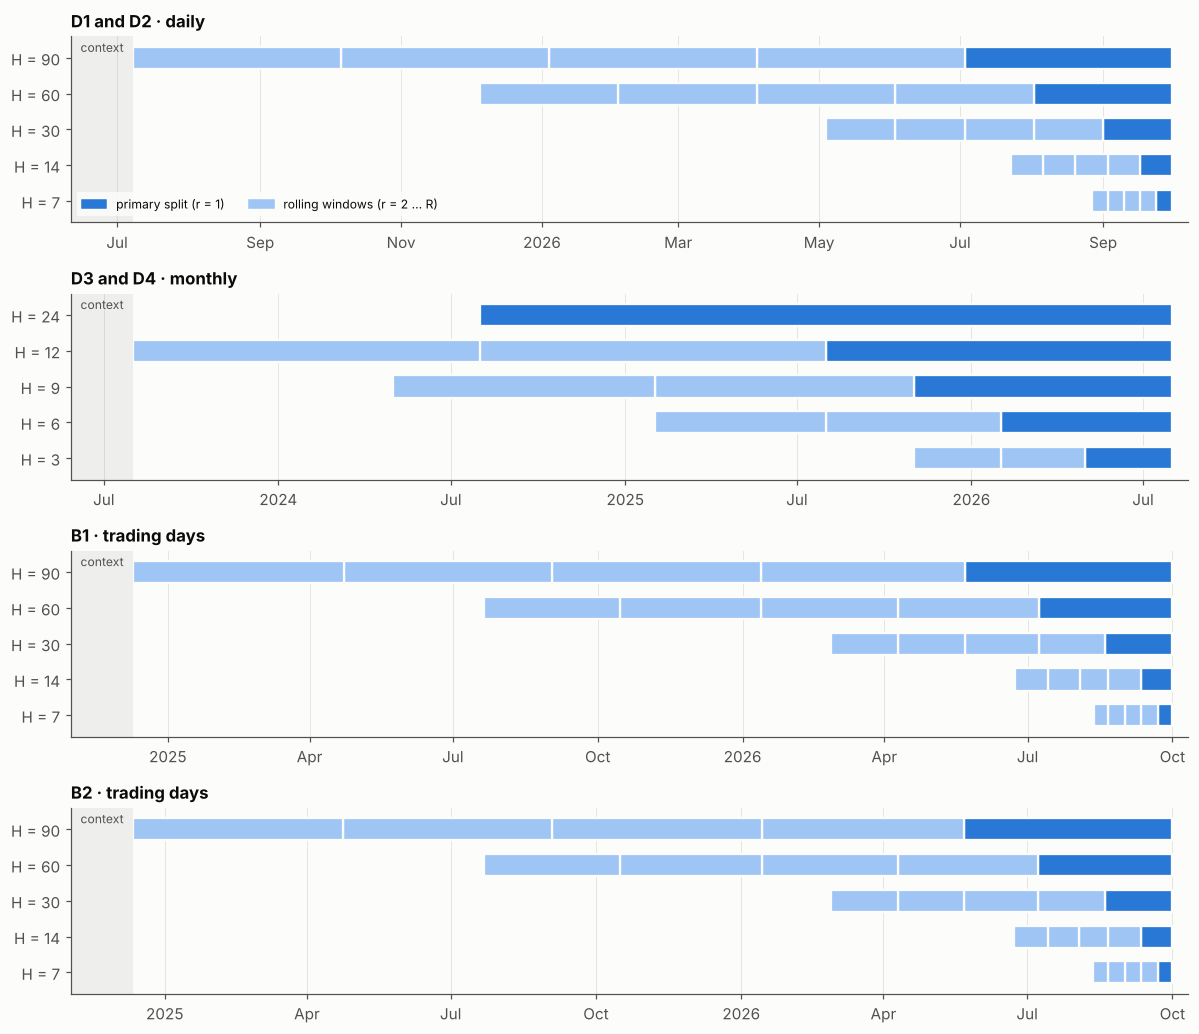

In [9]:
LIGHT = "#9ec5f4"     # a light step of the primary blue, for the rolling windows
CALENDARS = [("D1 and D2 · daily", "D1"), ("D3 and D4 · monthly", "D3"),
             ("B1 · trading days", "B1"), ("B2 · trading days", "B2")]
fig, axes = plt.subplots(len(CALENDARS), 1, figsize=(11, 9.5))
for ax, (title, name) in zip(axes, CALENDARS):
    m = manifest[manifest["dataset"] == name]
    horizons = sorted(m["horizon"].unique())
    idx = SNAP[name].index
    step = pd.offsets.MonthBegin(1) if grain_key(name) == "monthly" else pd.Timedelta(days=1)

    def bar_end(r):   # a window ends where the next row starts (for trading days: after the weekend)
        t_next = int(r["n_context"] + r["n_test"])
        return idx[t_next] if t_next < len(idx) else r["test_end"] + step

    for i, h in enumerate(horizons):
        for _, r in m[m["horizon"] == h].iterrows():
            start, end = mdates.date2num(r["test_start"]), mdates.date2num(bar_end(r))
            ax.barh(i, end - start, left=start, height=0.62, color=COLORS[0] if r["primary"] else LIGHT,
                    edgecolor=SURFACE, linewidth=1.5)
    first = mdates.date2num(m["test_start"].min())
    last = mdates.date2num(m["test_end"].max() + step)
    pad = 0.06 * (last - first)
    ax.axvspan(first - pad, first, color=INK_2, alpha=0.08, lw=0)
    ax.text(first - pad / 2, len(horizons) - 0.5, "context", ha="center", va="top", fontsize=8, color=INK_2)
    ax.set_xlim(first - pad, last + pad / 4)
    ax.set_yticks(range(len(horizons)), [f"H = {h}" for h in horizons])
    ax.set_ylim(-0.6, len(horizons) - 0.4)
    ax.grid(axis="y", visible=False)
    ax.set_axisbelow(True)
    locator = mdates.AutoDateLocator(minticks=5, maxticks=10)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    ax.set_title(title, loc="left")
axes[0].legend(handles=[Patch(color=COLORS[0], label="primary split (r = 1)"),
                        Patch(color=LIGHT, label="rolling windows (r = 2 ... R)")],
               loc="lower left", fontsize=8, ncol=2)
fig.tight_layout()
(RESULTS / "figures").mkdir(parents=True, exist_ok=True)
fig.savefig(RESULTS / "figures" / "fig_ch03_04_split_timeline.png", dpi=150)
plt.show()

## 5 · Covariates: what a model may read on the test side

Notebook 00 put every covariate of D2 and D4 into one of two classes, and the split has to respect them.

**Known-future covariates** can be computed for any date in advance. They are the annual Fourier terms, the sine
and cosine waves

$$\sin\negthinspace\left(\frac{2\pi k\thinspace d}{L}\right), \qquad \cos\negthinspace\left(\frac{2\pi k\thinspace d}{L}\right),$$

where $d$ is the day of the year counted from 0 on 1 January and $L$ the length of the year, and the astronomical
day length. A model may read them over the context **and** over the test window. D4 has none.

**Past-only covariates** are observed only as time passes. They are the causal wavelet bands of the temperature
itself, the NAO and AO indices (D2), and global activity, the dollar and the real rate (D4). A model may read them
up to the origin $T$ and **never** over the test window: their test-window values do not exist at the moment the
forecast is made, so using them would hand the model information from the future.

`split_frame` returns three blocks for a split:

- the **context**: the target and all covariates, rows $1$ to $T$;
- the **future** block: the known-future covariates only, rows $T+1$ to $T+H$;
- the **test** target: rows $T+1$ to $T+H$, used only for scoring.

It refuses to build a future block that contains a past-only covariate.

Three checks follow, run on every split of D2 and D4.

1. The blocks pass the leakage assertions of `split_frame`: the context ends at the origin, the test window starts
   on the next row, the future block has no past-only column, and the test window has length $H$.
2. The known-future values stored in D2 are reproduced exactly from the test dates alone, which shows that they
   need nothing but the calendar.
3. The wavelet bands recomputed from the **context alone** equal the stored bands over the context, which shows
   that the stored bands never used a value after the origin. The causal filter at the coarsest level reaches
   $2^8 - 1 = 255$ days into the past, so the comparison starts after the first 255 days of the context.

In [10]:
import numpy as np
import pandas as pd


def fourier_terms(index, k_max=3):
    """Annual Fourier terms sin/cos(2 pi k d / L), d = day of year, L = days in year.

    Deterministic, so they are known for any future date (known-future class).
    """
    idx = pd.DatetimeIndex(index)
    doy = idx.dayofyear.to_numpy() - 1
    year_len = np.where(idx.is_leap_year, 366.0, 365.0)
    out = {}
    for k in range(1, k_max + 1):
        ang = 2 * np.pi * k * doy / year_len
        out[f"fourier_sin_{k}"] = np.sin(ang)
        out[f"fourier_cos_{k}"] = np.cos(ang)
    return pd.DataFrame(out, index=idx)


def day_length_hours(index, latitude=52.5, p=0.8333):
    """Day length (hours) from the CBM model of Forsythe et al. (1995).

    theta = 0.2163108 + 2 atan(0.9671396 tan(0.00860 (J - 186)))   revolution angle
    phi   = asin(0.39795 cos(theta))                                 solar declination
    D     = 24 - (24 / pi) acos[(sin(p pi/180) + sin(L pi/180) sin(phi))
                                / (cos(L pi/180) cos(phi))]
    p = 0.8333 degrees: sunrise and sunset when the top of the sun is level
    with the horizon, including refraction (the usual almanac definition).
    """
    idx = pd.DatetimeIndex(index)
    j = idx.dayofyear.to_numpy().astype(float)
    theta = 0.2163108 + 2 * np.arctan(0.9671396 * np.tan(0.00860 * (j - 186)))
    phi = np.arcsin(0.39795 * np.cos(theta))
    lat = np.deg2rad(latitude)
    arg = (np.sin(np.deg2rad(p)) + np.sin(lat) * np.sin(phi)) / (np.cos(lat) * np.cos(phi))
    d = 24 - (24 / np.pi) * np.arccos(np.clip(arg, -1, 1))
    return pd.Series(d, index=idx, name="daylength_h")


def causal_haar_modwt(x, levels=8):
    """Causal Haar MODWT coefficients W_1..W_J and scaling coefficients V_J.

    Pyramid algorithm (Percival & Walden, 2000, ch. 5) with the Haar MODWT
    filters h = (1/2, -1/2), g = (1/2, 1/2):
        W_{j,t} = (V_{j-1,t} - V_{j-1,t-2^(j-1)}) / 2
        V_{j,t} = (V_{j-1,t} + V_{j-1,t-2^(j-1)}) / 2,   V_0 = X.
    Each value uses only X_t, X_{t-1}, ... (no future values), so it is a
    legitimate past-only covariate. The first 2^J - 1 values depend on the
    start of the record and are set to NaN (computed on the full record, they
    fall long before the 10,000-day window).
    """
    v = np.asarray(x, float)
    n = len(v)
    out = {}
    for j in range(1, levels + 1):
        lag = 2 ** (j - 1)
        shifted = np.full(n, np.nan)
        shifted[lag:] = v[:-lag]
        out[f"W{j}"] = (v - shifted) / 2
        v = (v + shifted) / 2
    out[f"V{levels}"] = v
    width = 2 ** levels - 1
    for key in out:
        out[key][:width] = np.nan
    return out


def wavelet_bands(series, levels=8):
    """Five causal band features from the Haar MODWT coefficients.

    wav_d1_2: W1 + W2 (periods of about 2 to 8 days), wav_d3_4: W3 + W4 (8 to 32),
    wav_d5_6: W5 + W6 (32 to 128), wav_d7_8: W7 + W8 (128 to 512), wav_s8: V8 (> 512).
    """
    c = causal_haar_modwt(np.asarray(series, float), levels)
    bands = {
        "wav_d1_2": c["W1"] + c["W2"], "wav_d3_4": c["W3"] + c["W4"],
        "wav_d5_6": c["W5"] + c["W6"], "wav_d7_8": c["W7"] + c["W8"],
        "wav_s8": c[f"V{levels}"],
    }
    return pd.DataFrame(bands, index=getattr(series, "index", None))

In [11]:
covariate_table = pd.DataFrame(
    [{"dataset": name, "covariate": col, "class": cls, "in context": "yes",
      "in future block": "yes" if cls == "known-future" else "no"}
     for name in ["D2", "D4"]
     for cls, key in [("known-future", "known_future"), ("past-only", "past_only")]
     for col in COVARIATES[name][key]]).set_index(["dataset", "covariate"])
covariate_table

class in context in future block
dataset covariate                                               
D2      fourier_sin_1    known-future        yes             yes
        fourier_cos_1    known-future        yes             yes
        fourier_sin_2    known-future        yes             yes
        fourier_cos_2    known-future        yes             yes
        daylength_h      known-future        yes             yes
        wav_d1_2            past-only        yes              no
        wav_d3_4            past-only        yes              no
        wav_d5_6            past-only        yes              no
        wav_d7_8            past-only        yes              no
        wav_s8              past-only        yes              no
        nao                 past-only        yes              no
        ao                  past-only        yes              no
D4      global_activity     past-only        yes              no
        usd                 past-only        yes              no
        real_rate_10y       past-only        yes              no

In [12]:
checks = {"leakage assertions": 0, "known-future values reproduced from dates": 0, "bands causal at the origin": 0}
max_gap = {"known-future": 0.0, "bands": 0.0}
for name in ["D2", "D4"]:
    known, past = COVARIATES[name]["known_future"], COVARIATES[name]["past_only"]
    for _, row in manifest[manifest["dataset"] == name].iterrows():
        context, future, test = split_frame(SNAP[name], row, past_only=past, known_future=known)
        checks["leakage assertions"] += 1
        if name == "D2":
            expected = pd.concat([fourier_terms(future.index, 3),
                                  day_length_hours(future.index, latitude=HADCET_LAT)], axis=1)[known]
            max_gap["known-future"] = max(max_gap["known-future"], float((future - expected).abs().max().max()))
            checks["known-future values reproduced from dates"] += 1
            bands = [c for c in past if c.startswith("wav_")]
            again = wavelet_bands(context["temp"]).iloc[255:]
            max_gap["bands"] = max(max_gap["bands"], float((context[bands].iloc[255:] - again).abs().max().max()))
            checks["bands causal at the origin"] += 1
for k, v in checks.items():
    print(f"{k}: {v} splits")
print(f"largest gap, known-future values vs. recomputed from dates: {max_gap['known-future']:.1e}")
print(f"largest gap, stored bands vs. recomputed from the context alone: {max_gap['bands']:.1e} C")
assert max_gap["known-future"] < 1e-9 and max_gap["bands"] < 1e-9, "a covariate check failed"

example = manifest[(manifest["dataset"] == "D2") & manifest["primary"] & (manifest["horizon"] == 30)].iloc[0]
context, future, test = split_frame(SNAP["D2"], example, COVARIATES["D2"]["past_only"], COVARIATES["D2"]["known_future"])
print(f"\nD2, primary split at H = 30: context {context.shape} (target + {context.shape[1] - 1} covariates), "
      f"future {future.shape} ({', '.join(future.columns)}), test {test.shape} ({', '.join(test.columns)})")

leakage assertions: 38 splits
known-future values reproduced from dates: 25 splits
bands causal at the origin: 25 splits
largest gap, known-future values vs. recomputed from dates: 1.8e-15
largest gap, stored bands vs. recomputed from the context alone: 1.8e-15 C

D2, primary split at H = 30: context (9970, 13) (target + 12 covariates), future (30, 5) (fourier_sin_1, fourier_cos_1, fourier_sin_2, fourier_cos_2, daylength_h), test (30, 1) (temp)


**What this tells us.** All 38 splits of D2 and D4 pass the leakage assertions. D2's known-future columns are
reproduced from the test dates alone to within 1.8 × 10⁻¹⁵, which is floating-point rounding. The wavelet bands
recomputed from each context alone match the stored ones to 1.8 × 10⁻¹⁵ °C, so no stored band uses a value from
after its origin.

In practice, a D2 model gets 12 covariates in its context and 5 (the Fourier terms and day length) over the test
window; a D4 model gets the 3 drivers in its context and none over the test window.

Many foundation models accept covariates, but not all accept the same kinds. Some take only past covariates, some
also take future ones, and some take none. The forecasting notebooks give each model what it can use from these
three blocks, so any gain from covariates measured there never comes from a leak.

## 6 · Could a checkpoint have seen the test window?

A pre-trained model can only have learned from data that existed when its weights were saved. We record, for each
checkpoint, the date of the last commit that changed its weight files on Hugging Face (in
`data/model_checkpoint_dates.csv`, looked up on the date given in its `checked_utc` column). That date is an
**upper bound** on the date its training data stop. For a split whose test window starts on date $s$, and a
checkpoint whose weights date is $w$:

- if $w < s$, the test window did not yet exist when the weights were saved, so the checkpoint **cannot** have seen
  it;
- if $w \ge s$, the checkpoint *could* have seen it, but only if its pre-training data contain this very series.
  This is a flag, not a finding. Most pre-training collections are documented, and the forecasting notebooks check
  the flagged cases against each model's data card.

The bound is cautious: training data usually stop months before the weights are uploaded, so a flag can only err
on the safe side.

In [13]:
checkpoints = pd.read_csv(DATA / "model_checkpoint_dates.csv")
manifest = checkpoint_overlap(manifest, checkpoints)
weights = pd.to_datetime(checkpoints.set_index("model")["weights_last_commit_utc"]).sort_values()

exposure = pd.DataFrame({name: [int((manifest.loc[manifest["dataset"] == name, "test_start"] <= w).sum())
                                for w in weights] for name in DATASETS}, index=weights.index)
exposure.insert(0, "weights date", weights.dt.date)
n_windows = manifest.groupby("dataset").size()
print("Test windows that each checkpoint could have seen (out of " +
      ", ".join(f"{k} {v}" for k, v in n_windows.items()) + "):")
exposure

Test windows that each checkpoint could have seen (out of B1 25, B2 25, D1 25, D2 25, D3 13, D4 13):


,weights date,D1,D2,D3,D4,B1,B2
model,,,,,,,
lag-llama,2024-02-07,0,0,1,1,0,0
moirai11,2024-06-14,0,0,2,2,0,0
timemoe,2024-09-21,0,0,4,4,0,0
ttm,2024-10-09,0,0,4,4,0,0
moment,2024-10-10,0,0,4,4,0,0
moirai-moe,2024-11-01,0,0,4,4,0,0
chronos-bolt,2024-11-13,0,0,4,4,0,0
timer,2024-12-01,0,0,4,4,0,0
toto1,2025-05-06,0,0,6,6,2,2


In [14]:
for name in DATASETS:
    m = manifest[manifest["dataset"] == name]
    clean = [model for model, w in weights.items() if w < m["test_start"].min()]
    primary_clean = [model for model, w in weights.items() if w < m.loc[m["primary"], "test_start"].min()]
    print(f"{name}: earliest test date {m['test_start'].min().date()}; "
          f"{len(clean)} of {len(weights)} checkpoints predate every test window, "
          f"{len(primary_clean)} predate every primary window")
flagged = manifest.loc[manifest["primary"], ["dataset", "horizon", "test_start", "n_models_flagged",
                                              "models_weights_after_test_start"]]
flagged[flagged["n_models_flagged"] > 0].set_index(["dataset", "horizon"])

D1: earliest test date 2025-07-08; 12 of 28 checkpoints predate every test window, 22 predate every primary window
D2: earliest test date 2025-07-08; 12 of 28 checkpoints predate every test window, 22 predate every primary window
D3: earliest test date 2023-08-01; 0 of 28 checkpoints predate every test window, 2 predate every primary window
D4: earliest test date 2023-08-01; 0 of 28 checkpoints predate every test window, 2 predate every primary window
B1: earliest test date 2024-12-10; 8 of 28 checkpoints predate every test window, 22 predate every primary window
B2: earliest test date 2024-12-12; 8 of 28 checkpoints predate every test window, 22 predate every primary window


test_start  n_models_flagged                    models_weights_after_test_start
dataset horizon                                                                                
D1      7       2026-09-24                 4                t0, timestral, timestral-5m, tirex2
        14      2026-09-17                 4                t0, timestral, timestral-5m, tirex2
        30      2026-09-01                 4                t0, timestral, timestral-5m, tirex2
        60      2026-08-02                 6  patchtst-fm, t0, timesfm3, timestral, timestra...
        90      2026-07-03                 6  patchtst-fm, t0, timesfm3, timestral, timestra...
D2      7       2026-09-24                 4                t0, timestral, timestral-5m, tirex2
        14      2026-09-17                 4                t0, timestral, timestral-5m, tirex2
        30      2026-09-01                 4                t0, timestral, timestral-5m, tirex2
        60      2026-08-02                 6  patchtst-fm, t0, timesfm3, timestral, timestra...
        90      2026-07-03                 6  patchtst-fm, t0, timesfm3, timestral, timestra...
D3      3       2026-05-01                 6  patchtst-fm, t0, timesfm3, timestral, timestra...
        6       2026-02-01                 9  flowstate, patchtst-fm, t0, timer-s1, timesfm3...
        9       2025-11-01                12  chronos2-small, flowstate, patchtst-fm, t0, ta...
        12      2025-08-01                16  chronos2, chronos2-small, flowstate, kairos, m...
        24      2024-08-01                26  chronos-bolt, chronos2, chronos2-small, flowst...
D4      3       2026-05-01                 6  patchtst-fm, t0, timesfm3, timestral, timestra...
        6       2026-02-01                 9  flowstate, patchtst-fm, t0, timer-s1, timesfm3...
        9       2025-11-01                12  chronos2-small, flowstate, patchtst-fm, t0, ta...
        12      2025-08-01                16  chronos2, chronos2-small, flowstate, kairos, m...
        24      2024-08-01                26  chronos-bolt, chronos2, chronos2-small, flowst...
B1      7       2026-09-22                 4                t0, timestral, timestral-5m, tirex2
        14      2026-09-11                 4                t0, timestral, timestral-5m, tirex2
        30      2026-08-19                 6  patchtst-fm, t0, timesfm3, timestral, timestra...
        60      2026-07-08                 6  patchtst-fm, t0, timesfm3, timestral, timestra...
        90      2026-05-22                 6  patchtst-fm, t0, timesfm3, timestral, timestra...
B2      7       2026-09-22                 4                t0, timestral, timestral-5m, tirex2
        14      2026-09-11                 4                t0, timestral, timestral-5m, tirex2
        30      2026-08-19                 6  patchtst-fm, t0, timesfm3, timestral, timestra...
        60      2026-07-08                 6  patchtst-fm, t0, timesfm3, timestral, timestra...
        90      2026-05-22                 6  patchtst-fm, t0, timesfm3, timestral, timestra...

**What this tells us.** For D1 and D2, 22 of the 28 checkpoints predate every primary test window. The six that do
not (`timesfm3`, `patchtst-fm`, `tirex2`, `t0`, `timestral` and `timestral-5m`) were uploaded between August and
October 2026. Over all windows, which reach back to July 2025, 12 checkpoints predate every window. B1 and B2 look
similar (22 and 8).

The monthly D3 and D4 are the most exposed. Their windows reach back to August 2023, so no checkpoint predates every
window, and only `lag-llama` and `moirai11` predate every primary one.

A flag only means that the test data existed when the weights were saved. Whether a model's pre-training data
contain HadCET, LME prices, WTI or Treasury yields is checked against its data card in the forecasting notebooks.

## 7 · Save the split manifest

The notebook writes three outputs. All of them come from the frozen snapshot, so running the notebook again
reproduces them exactly.

- `data/splits/split_manifest.csv`: one row per dataset, horizon and window, with dates, row counts and the
  checkpoint flags.
- `data/splits/<dataset>.json`: the same rows for one dataset, plus its targets and its two covariate lists. This
  is everything a forecasting notebook needs to build a model's inputs.
- the **Splits** sheet of `input_timeseries/data_dictionary_ch03.xlsx`: one line per dataset and horizon, with the
  origin dates.

In [15]:
out_dir = DATA / "splits"
out_dir.mkdir(parents=True, exist_ok=True)
date_cols = ["origin_date", "context_start", "context_end", "test_start", "test_end"]
saved = manifest.copy()
for c in date_cols:
    saved[c] = saved[c].dt.strftime("%Y-%m-%d")
saved.to_csv(out_dir / "split_manifest.csv", index=False)

for name, spec in DATASETS.items():
    rows = saved[saved["dataset"] == name].drop(columns=["models_weights_after_test_start"])
    payload = {"dataset": name, "name": spec["name"], "grain": spec["grain"], "targets": spec["targets"],
               "known_future": COVARIATES.get(name, {}).get("known_future", []),
               "past_only": COVARIATES.get(name, {}).get("past_only", []),
               "horizons": HORIZONS[grain_key(name)],
               "rolling_windows": {str(h): ROLLING_WINDOWS[grain_key(name)][h] for h in HORIZONS[grain_key(name)]},
               "snapshot": SNAPSHOT["vintage_cut"], "splits": rows.to_dict(orient="records")}
    (out_dir / f"{name}.json").write_text(json.dumps(payload, indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o)))

sheet = (manifest.groupby(["dataset", "horizon"])
         .apply(lambda g: pd.Series({
             "windows": len(g), "test_points_per_series": int(g["n_test"].sum()),
             "origin_dates": "; ".join(g.sort_values("window")["origin_date"].dt.strftime("%Y-%m-%d")),
             "context_rows_primary": int(g.loc[g["primary"], "n_context"].iloc[0]),
             "checkpoints_flagged_primary": int(g.loc[g["primary"], "n_models_flagged"].iloc[0])}),
                include_groups=False)
         .reset_index())
with pd.ExcelWriter(INPUT / "data_dictionary_ch03.xlsx", mode="a", engine="openpyxl", if_sheet_exists="replace") as xl:
    sheet.to_excel(xl, sheet_name="Splits", index=False)
    ws = xl.book["Splits"]
    ws.freeze_panes = "A2"
    for column in ws.columns:
        width = max(len(str(c.value)) if c.value is not None else 0 for c in column)
        ws.column_dimensions[column[0].column_letter].width = min(max(10, width + 2), 70)
print(f"saved {len(saved)} splits to {out_dir} ({len(DATASETS)} JSON files) and the Splits sheet of the data dictionary")
sheet.head(10)

saved 126 splits to /home/user/v3/Chapter03_Zero_Shot_Forecasting/data/splits (6 JSON files) and the Splits sheet of the data dictionary


,dataset,horizon,windows,test_points_per_series,origin_dates,context_rows_primary,checkpoints_flagged_primary
0,B1,7,5,35,2026-09-21; 2026-09-10; 2026-08-31; 2026-08-20...,9506,4
1,B1,14,5,70,2026-09-10; 2026-08-20; 2026-07-31; 2026-07-13...,9499,4
2,B1,30,5,150,2026-08-18; 2026-07-07; 2026-05-21; 2026-04-09...,9483,6
3,B1,60,5,300,2026-07-07; 2026-04-09; 2026-01-12; 2025-10-14...,9453,6
4,B1,90,5,450,2026-05-21; 2026-01-12; 2025-08-29; 2025-04-22...,9423,6
5,B2,7,5,35,2026-09-21; 2026-09-10; 2026-08-31; 2026-08-20...,9993,4
6,B2,14,5,70,2026-09-10; 2026-08-20; 2026-07-31; 2026-07-13...,9986,4
7,B2,30,5,150,2026-08-18; 2026-07-07; 2026-05-21; 2026-04-09...,9970,6
8,B2,60,5,300,2026-07-07; 2026-04-09; 2026-01-13; 2025-10-15...,9940,6
9,B2,90,5,450,2026-05-21; 2026-01-13; 2025-09-02; 2025-04-23...,9910,6


## 8 · How the forecasting notebooks use the splits

Every forecasting notebook starts with the same three steps: read a dataset and its split file, pick a split, and
ask `split_frame` for the blocks. The model receives `context`, and `future` too if it accepts known-future
covariates. `test` is used only to score the forecast.

In [16]:
spec = json.loads((DATA / "splits" / "D2.json").read_text())
row = pd.Series(next(s for s in spec["splits"] if s["horizon"] == 7 and s["window"] == 1))
row[["origin_date", "test_start", "test_end"]] = pd.to_datetime(row[["origin_date", "test_start", "test_end"]])
context, future, test = split_frame(SNAP["D2"], row, spec["past_only"], spec["known_future"])
print(f"context: {context.index[0].date()} to {context.index[-1].date()} ({len(context):,} rows)")
print(f"future block: {list(future.columns)}")
print(f"test: {test.index[0].date()} to {test.index[-1].date()} ({len(test)} rows)")

context: 1999-05-16 to 2026-09-23 (9,993 rows)
future block: ['fourier_sin_1', 'fourier_cos_1', 'fourier_sin_2', 'fourier_cos_2', 'daylength_h']
test: 2026-09-24 to 2026-09-30 (7 rows)


## Key takeaways

- Four things fix the split of a dataset: the number of rows $N$, the horizons, the number of windows $R$ and the
  origin rule $T_r = N - rH$. Every later notebook reads the split from `data/splits/` instead of recomputing it.
- Rolling windows move the origin back by whole horizons, so the test windows of one horizon never overlap and
  every test point counts once.
- In a zero-shot study the "train" rows are the model's context. The same rows are the training set of the
  statistical baselines, which keeps the comparison fair.
- Known-future covariates may be read over the test window; past-only covariates may not. Both rules are enforced
  in code and checked on every split, including a recomputation of the wavelet bands from the context alone.
- The date a checkpoint's weights were saved bounds what it can have seen. Test windows that start after that date
  are certainly unseen; earlier ones are flagged for a closer look at the model's data card.

## References

- Rolling-origin evaluation (Section 1): Tashman, L. J. (2000). Out-of-sample tests of forecasting accuracy: an analysis and review. *International Journal of Forecasting*, 16(4), 437–450. [doi:10.1016/S0169-2070(00)00065-0](https://doi.org/10.1016/S0169-2070(00)00065-0)
- Time series cross-validation (Section 1): Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and Practice* (3rd ed.), Section 5.10, Time series cross-validation. OTexts. [otexts.com/fpp3/tscv.html](https://otexts.com/fpp3/tscv.html)
- The GIFT-Eval benchmark (Section 1): Aksu, T., Woo, G., Liu, J., Liu, X., Liu, C., Savarese, S., Xiong, C., & Sahoo, D. (2024). GIFT-Eval: a benchmark for general time series forecasting model evaluation. Preprint, [arXiv:2410.10393](https://arxiv.org/abs/2410.10393)
- The causal Haar wavelet filter and its start-up length (Section 5): Percival, D. B., & Walden, A. T. (2000). *Wavelet Methods for Time Series Analysis*. Cambridge University Press. [doi:10.1017/CBO9780511841040](https://doi.org/10.1017/CBO9780511841040)
- Day length (Section 5): Forsythe, W. C., Rykiel, E. J., Stahl, R. S., Wu, H., & Schoolfield, R. M. (1995). A model comparison for daylength as a function of latitude and day of year. *Ecological Modelling*, 80(1), 87–95. [doi:10.1016/0304-3800(94)00034-F](https://doi.org/10.1016/0304-3800(94)00034-F)